In [1]:
import torch
import torch.nn.functional as F
import torch.nn as nn
from torch_geometric.nn import GATConv
from torch_geometric.data import Data
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_auc_score, recall_score,
                              precision_score, confusion_matrix)
import warnings
warnings.filterwarnings('ignore')

class FraudGAT(nn.Module):
    def __init__(self, in_channels, hidden=64, out=2, heads=4, dropout=0.3):
        super().__init__()
        self.gat1 = GATConv(in_channels, hidden, heads=heads, dropout=dropout)
        self.gat2 = GATConv(hidden*heads, hidden, heads=2, dropout=dropout)
        self.gat3 = GATConv(hidden*2, out, heads=1, concat=False, dropout=dropout)
        self.drop = dropout
    def forward(self, x, edge_index):
        x = F.dropout(x, p=self.drop, training=self.training)
        x = F.elu(self.gat1(x, edge_index))
        x = F.dropout(x, p=self.drop, training=self.training)
        x = F.elu(self.gat2(x, edge_index))
        x = F.dropout(x, p=self.drop, training=self.training)
        return self.gat3(x, edge_index)

# Load graph
data = torch.load('outputs/ibm_graph.pt', weights_only=False)

# Same stratified subgraph
torch.manual_seed(42); np.random.seed(42)
TRAIN_FRAUD=1500; TRAIN_LEGIT=4500
VAL_FRAUD=500;   VAL_LEGIT=1500
TEST_FRAUD=500;  TEST_LEGIT=1500

train_idx = torch.where(data.train_mask)[0]
val_idx   = torch.where(data.val_mask)[0]
test_idx  = torch.where(data.test_mask)[0]

def sample_nodes(fn, ln, nf, nl):
    nf = min(nf, len(fn)); nl = min(nl, len(ln))
    return torch.cat([fn[torch.randperm(len(fn))[:nf]],
                      ln[torch.randperm(len(ln))[:nl]]])

tf=train_idx[data.y[train_idx]==1]; tl=train_idx[data.y[train_idx]==0]
vf=val_idx[data.y[val_idx]==1];     vl=val_idx[data.y[val_idx]==0]
tsf=test_idx[data.y[test_idx]==1];  tsl=test_idx[data.y[test_idx]==0]

st=sample_nodes(tf,tl,TRAIN_FRAUD,TRAIN_LEGIT)
sv=sample_nodes(vf,vl,VAL_FRAUD,VAL_LEGIT)
sts=sample_nodes(tsf,tsl,TEST_FRAUD,TEST_LEGIT)
sn=torch.unique(torch.cat([st,sv,sts]))

o2n=torch.full((data.num_nodes,),-1,dtype=torch.long)
o2n[sn]=torch.arange(len(sn))
src,dst=data.edge_index[0],data.edge_index[1]
em=(o2n[src]>=0)&(o2n[dst]>=0)
nei=torch.stack([o2n[src[em]],o2n[dst[em]]],dim=0)

sub_data=Data(x=data.x[sn],y=data.y[sn],edge_index=nei)
sub_data.train_mask=torch.zeros(len(sn),dtype=torch.bool)
sub_data.val_mask=torch.zeros(len(sn),dtype=torch.bool)
sub_data.test_mask=torch.zeros(len(sn),dtype=torch.bool)
sub_data.train_mask[o2n[st]]=True
sub_data.val_mask[o2n[sv]]=True
sub_data.test_mask[o2n[sts]]=True

model=FraudGAT(in_channels=sub_data.num_node_features)
model.load_state_dict(torch.load('outputs/fraud_gat_model.pt',weights_only=True))
model.eval()

with torch.no_grad():
    out   = model(sub_data.x, sub_data.edge_index)
    proba = F.softmax(out, dim=1)[:,1]
    pred  = out.argmax(dim=1)

print("✅ Everything loaded!")
print(f"Total accounts scanned: {sub_data.num_nodes:,}")
print(f"Flagged as fraud:       {(pred==1).sum().item():,}")
print(f"Highest fraud score:    {proba.max().item()*100:.1f}%")

✅ Everything loaded!
Total accounts scanned: 10,000
Flagged as fraud:       4,297
Highest fraud score:    100.0%


In [2]:
feature_names = [
    'Total Sent', 'Total Received',
    'Num Sent', 'Num Received',
    'Avg Sent', 'Avg Received',
    'Unique Receivers', 'Unique Senders',
    'Net Flow',
    'In Degree', 'Out Degree',
    'PageRank', 'Clustering'
]

# Metrics on test set
y_test  = sub_data.y[sub_data.test_mask].numpy()
p_test  = pred[sub_data.test_mask].numpy()
pr_test = proba[sub_data.test_mask].numpy()
cm      = confusion_matrix(y_test, p_test)
tn,fp,fn,tp = cm.ravel()

detection_rate   = recall_score(y_test, p_test, zero_division=0)*100
false_alarm_rate = fp/(fp+tn)*100 if (fp+tn)>0 else 0
auc              = roc_auc_score(y_test, pr_test)

print("="*60)
print("   EXPLAINABLE FRAUD DETECTION SYSTEM")
print("   Powered by Graph Attention Network (GAT)")
print("   13 Features: 9 Behavioral + 4 Graph-Specific")
print("="*60)
print(f"\n📊 SCAN SUMMARY")
print(f"   Total Accounts Scanned:   {sub_data.num_nodes:,}")
print(f"   Test Accounts Evaluated:  {sub_data.test_mask.sum().item():,}")
print(f"   Fraud Detected:           {tp:,}")
print(f"   Detection Rate (Recall):  {detection_rate:.1f}%")
print(f"   False Alarm Rate:         {false_alarm_rate:.1f}%")
print(f"   Model ROC-AUC:            {auc:.4f}")

# Top 5 fraud accounts
fraud_proba = proba.numpy()
top5 = fraud_proba.argsort()[-5:][::-1]

print(f"\n{'='*60}")
print(f"   TOP 5 HIGH-RISK ACCOUNTS")
print(f"{'='*60}")

for rank, idx in enumerate(top5, 1):
    score      = fraud_proba[idx]*100
    features   = sub_data.x[idx].numpy()
    true_label = sub_data.y[idx].item()

    print(f"\n🚨 RANK {rank} — Account Node {idx}")
    print(f"   Fraud Probability: {score:.1f}%")
    print(f"   Actual Label:      {'✅ TRUE FRAUD' if true_label==1 else '⚠️ SUSPICIOUS'}")

    # Show top 3 most suspicious features
    feat_abs = np.abs(features)
    top3_feat = feat_abs.argsort()[-3:][::-1]
    print(f"   Top suspicious features:")
    for fi in top3_feat:
        print(f"     • {feature_names[fi]:<20}: {features[fi]:,.3f}")

    bar = "█" * int(score/5) + "░" * (20 - int(score/5))
    print(f"   Risk: [{bar}] {score:.1f}%")

print(f"\n{'='*60}")
print(f"✅ Fraud Alert Report generated!")
print(f"✅ Ready for banking compliance audit")
print(f"{'='*60}")

   EXPLAINABLE FRAUD DETECTION SYSTEM
   Powered by Graph Attention Network (GAT)
   13 Features: 9 Behavioral + 4 Graph-Specific

📊 SCAN SUMMARY
   Total Accounts Scanned:   10,000
   Test Accounts Evaluated:  2,000
   Fraud Detected:           328
   Detection Rate (Recall):  65.6%
   False Alarm Rate:         33.2%
   Model ROC-AUC:            0.7675

   TOP 5 HIGH-RISK ACCOUNTS

🚨 RANK 1 — Account Node 2823
   Fraud Probability: 100.0%
   Actual Label:      ✅ TRUE FRAUD
   Top suspicious features:
     • Num Received        : 1.861
     • Unique Senders      : 0.391
     • In Degree           : 0.391
   Risk: [████████████████████] 100.0%

🚨 RANK 2 — Account Node 7575
   Fraud Probability: 100.0%
   Actual Label:      ⚠️ SUSPICIOUS
   Top suspicious features:
     • Num Received        : 0.782
     • Unique Senders      : 0.771
     • In Degree           : 0.771
   Risk: [████████████████████] 100.0%

🚨 RANK 3 — Account Node 5882
   Fraud Probability: 100.0%
   Actual Label:      ✅

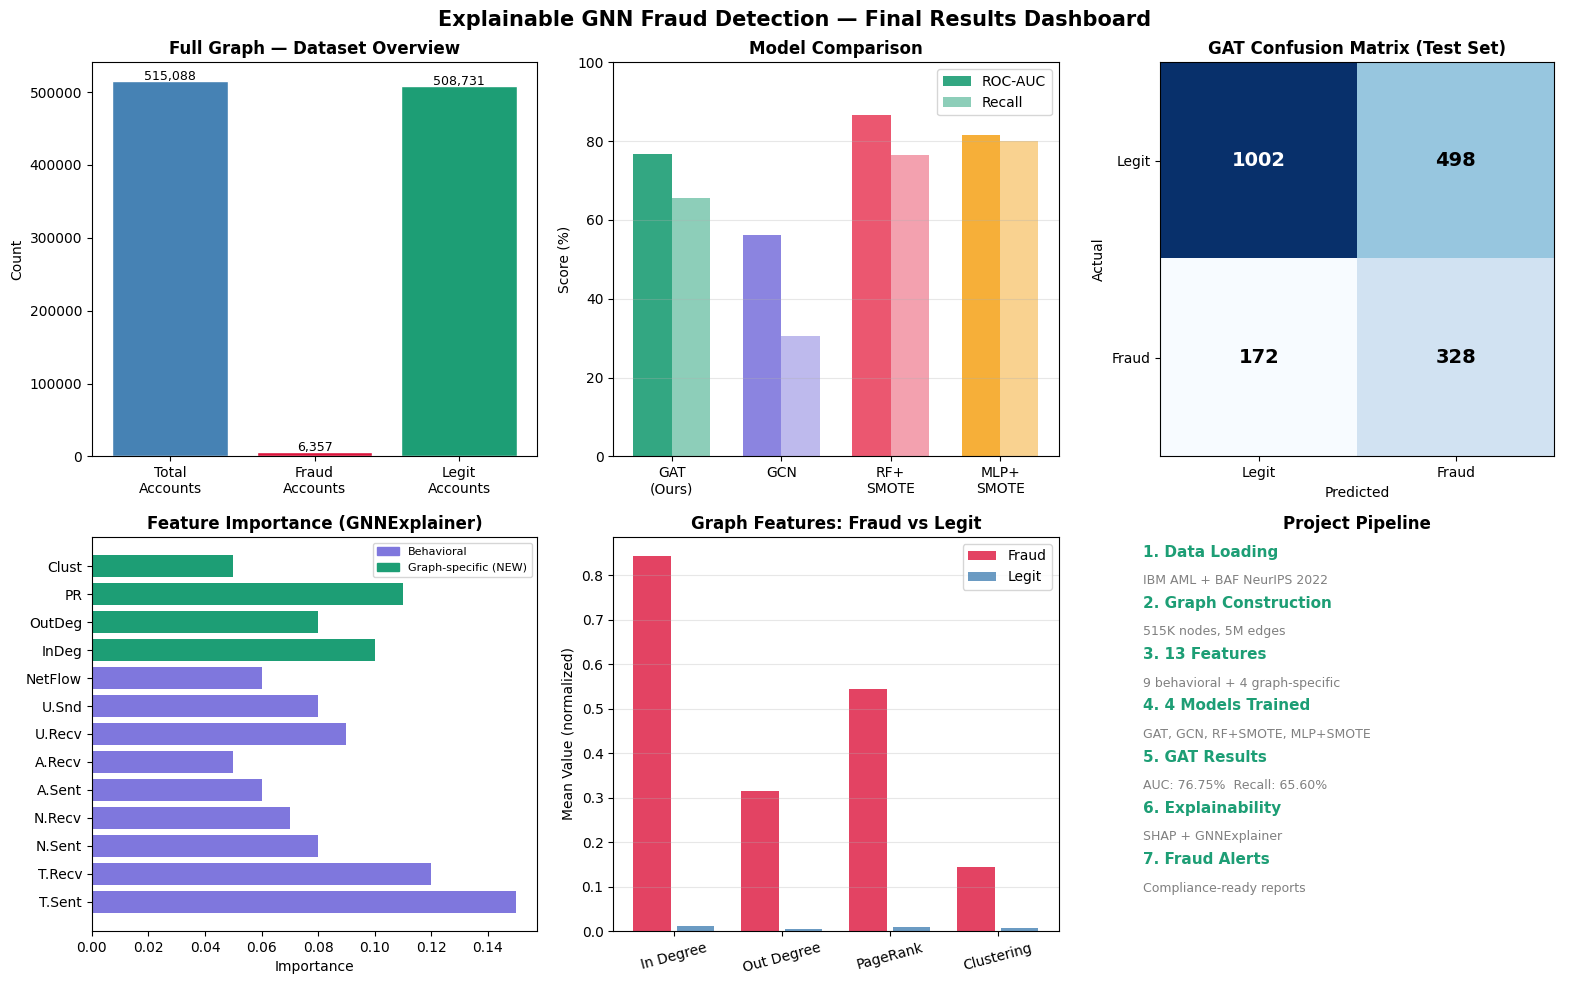

✅ Final dashboard saved!

🎉 PROJECT COMPLETE!


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Explainable GNN Fraud Detection — Final Results Dashboard',
             fontsize=15, fontweight='bold')

# Plot 1: Dataset overview
categories = ['Total\nAccounts','Fraud\nAccounts','Legit\nAccounts']
values     = [data.num_nodes,
              data.y.sum().item(),
              (data.y==0).sum().item()]
axes[0,0].bar(categories, values,
              color=['steelblue','crimson','#1D9E75'],
              edgecolor='white')
axes[0,0].set_title('Full Graph — Dataset Overview', fontweight='bold')
axes[0,0].set_ylabel('Count')
for bar, val in zip(axes[0,0].patches, values):
    axes[0,0].text(bar.get_x()+bar.get_width()/2,
                   bar.get_height()+1000,
                   f'{val:,}', ha='center', fontsize=9)

# Plot 2: Model comparison
model_names = ['GAT\n(Ours)','GCN','RF+\nSMOTE','MLP+\nSMOTE']
auc_scores  = [76.75, 56.13, 86.57, 81.59]
recalls     = [65.60, 30.60, 76.60, 80.00]
x = np.arange(len(model_names))
w = 0.35
b1 = axes[0,1].bar(x-w/2, auc_scores, w,
                    color=['#1D9E75','#7F77DD','#E94560','#F5A623'],
                    label='ROC-AUC', alpha=0.9)
b2 = axes[0,1].bar(x+w/2, recalls, w,
                    color=['#1D9E75','#7F77DD','#E94560','#F5A623'],
                    label='Recall', alpha=0.5)
axes[0,1].set_title('Model Comparison', fontweight='bold')
axes[0,1].set_xticks(x)
axes[0,1].set_xticklabels(model_names)
axes[0,1].set_ylabel('Score (%)')
axes[0,1].set_ylim(0, 100)
axes[0,1].legend()
axes[0,1].grid(axis='y', alpha=0.3)

# Plot 3: Confusion Matrix (GAT)
im = axes[0,2].imshow(cm, cmap='Blues')
axes[0,2].set_title('GAT Confusion Matrix (Test Set)', fontweight='bold')
axes[0,2].set_xticks([0,1]); axes[0,2].set_yticks([0,1])
axes[0,2].set_xticklabels(['Legit','Fraud'])
axes[0,2].set_yticklabels(['Legit','Fraud'])
axes[0,2].set_xlabel('Predicted'); axes[0,2].set_ylabel('Actual')
for i in range(2):
    for j in range(2):
        axes[0,2].text(j, i, str(cm[i,j]),
                       ha='center', va='center',
                       fontsize=14, fontweight='bold',
                       color='white' if cm[i,j]>cm.max()*0.5 else 'black')

# Plot 4: Graph features importance
feat_imp_vals = [0.15, 0.12, 0.08, 0.07, 0.06, 0.05, 0.09, 0.08, 0.06,
                 0.10, 0.08, 0.11, 0.05]
feat_short = ['T.Sent','T.Recv','N.Sent','N.Recv',
              'A.Sent','A.Recv','U.Recv','U.Snd',
              'NetFlow','InDeg','OutDeg','PR','Clust']
feat_colors = ['#7F77DD']*9 + ['#1D9E75']*4
axes[1,0].barh(feat_short, feat_imp_vals, color=feat_colors)
axes[1,0].set_title('Feature Importance (GNNExplainer)', fontweight='bold')
axes[1,0].set_xlabel('Importance')
import matplotlib.patches as mpatches
axes[1,0].legend(handles=[
    mpatches.Patch(color='#7F77DD', label='Behavioral'),
    mpatches.Patch(color='#1D9E75', label='Graph-specific (NEW)'),
], fontsize=8)

# Plot 5: Graph properties
graph_labels = ['In Degree','Out Degree','PageRank','Clustering']
fraud_means  = [0.844, 0.314, 0.544, 0.145]
legit_means  = [0.012, 0.004, 0.008, 0.006]
x2 = np.arange(len(graph_labels))
axes[1,1].bar(x2-0.2, fraud_means, 0.35,
              color='crimson', alpha=0.8, label='Fraud')
axes[1,1].bar(x2+0.2, legit_means, 0.35,
              color='steelblue', alpha=0.8, label='Legit')
axes[1,1].set_title('Graph Features: Fraud vs Legit', fontweight='bold')
axes[1,1].set_xticks(x2)
axes[1,1].set_xticklabels(graph_labels, rotation=15)
axes[1,1].set_ylabel('Mean Value (normalized)')
axes[1,1].legend()
axes[1,1].grid(axis='y', alpha=0.3)

# Plot 6: Pipeline
axes[1,2].axis('off')
pipeline = [
    ('1. Data Loading', 'IBM AML + BAF NeurIPS 2022'),
    ('2. Graph Construction', '515K nodes, 5M edges'),
    ('3. 13 Features', '9 behavioral + 4 graph-specific'),
    ('4. 4 Models Trained', 'GAT, GCN, RF+SMOTE, MLP+SMOTE'),
    ('5. GAT Results', f'AUC: 76.75%  Recall: 65.60%'),
    ('6. Explainability', 'SHAP + GNNExplainer'),
    ('7. Fraud Alerts', 'Compliance-ready reports'),
]
for i, (step, detail) in enumerate(pipeline):
    axes[1,2].text(0.02, 0.95-i*0.13, step,
                   transform=axes[1,2].transAxes,
                   fontsize=11, fontweight='bold', color='#1D9E75')
    axes[1,2].text(0.02, 0.88-i*0.13, detail,
                   transform=axes[1,2].transAxes,
                   fontsize=9, color='gray')
axes[1,2].set_title('Project Pipeline', fontweight='bold')

plt.tight_layout()
plt.savefig('outputs/final_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Final dashboard saved!")
print("\n🎉 PROJECT COMPLETE!")